# BÀI 5: GOM CỤM DỮ LIỆU MNIST5 BẰNG THUẬT TOÁN K-MEANS


## Import thư viện

In [1]:
print("NguyenDucTinh - 6451071077")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist

from sklearn.cluster import KMeans
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    classification_report
)

from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment

NguyenDucTinh - 6451071077


## Đọc dữ liệu MNIST

NguyenDucTinh - 6451071077
Kích thước X_train: (60000, 28, 28)
Kích thước y_train: (60000,)
Kích thước X_test: (10000, 28, 28)
Kích thước y_test: (10000,)


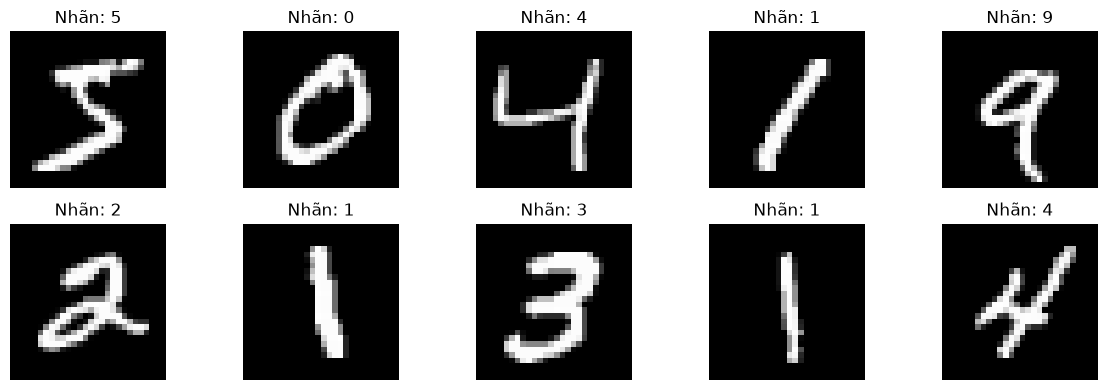

In [2]:
print("NguyenDucTinh - 6451071077")

# Đọc dữ liệu MNIST từ thư viện Keras
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# In kích thước dữ liệu
print("Kích thước X_train:", X_train.shape)
print("Kích thước y_train:", y_train.shape)

print("Kích thước X_test:", X_test.shape)
print("Kích thước y_test:", y_test.shape)

# Hiển thị 10 ảnh đầu tiên
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title("Nhãn: " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

## Tiền xử lý dữ liệu

In [3]:
print("NguyenDucTinh - 6451071077")

# Chuyển ảnh 28x28 thành vector 784 chiều
X_train_flat = X_train.reshape(X_train.shape[0], 784)

# Chuẩn hóa dữ liệu về khoảng [0, 1]
X_train_scaled = X_train_flat.astype('float32') / 255.0

# Lấy 10000 mẫu để thực hiện gom cụm
np.random.seed(42)

indices = np.random.choice(
    X_train_scaled.shape[0],
    10000,
    replace=False
)

X_sample = X_train_scaled[indices]
y_sample = y_train[indices]

print("Kích thước dữ liệu sau khi làm phẳng:", X_train_flat.shape)
print("Kích thước dữ liệu sau khi chuẩn hóa:", X_train_scaled.shape)

print("Kích thước dữ liệu sử dụng gom cụm:", X_sample.shape)
print("Kích thước nhãn tương ứng:", y_sample.shape)

NguyenDucTinh - 6451071077
Kích thước dữ liệu sau khi làm phẳng: (60000, 784)
Kích thước dữ liệu sau khi chuẩn hóa: (60000, 784)
Kích thước dữ liệu sử dụng gom cụm: (10000, 784)
Kích thước nhãn tương ứng: (10000,)


## Xây dựng mô hình k-Means

In [4]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo mô hình KMeans với 10 cụm
kmeans = KMeans(
    n_clusters=10,
    init='k-means++',
    n_init=10,
    random_state=42
)

# Huấn luyện mô hình
kmeans.fit(X_sample)

# Dự đoán cụm cho từng mẫu dữ liệu
y_cluster = kmeans.labels_

# In kết quả
print("Đã hoàn thành quá trình gom cụm bằng KMeans")

print("Số lượng cụm:", kmeans.n_clusters)

print("Kích thước tâm cụm:", kmeans.cluster_centers_.shape)

print("Giá trị Inertia:", kmeans.inertia_)

print("\nSố lượng mẫu trong từng cụm:")

for i in range(10):
    print(
        "Cụm", i, ":",
        np.sum(y_cluster == i),
        "mẫu"
    )

NguyenDucTinh - 6451071077
Đã hoàn thành quá trình gom cụm bằng KMeans
Số lượng cụm: 10
Kích thước tâm cụm: (10, 784)
Giá trị Inertia: 391398.65625

Số lượng mẫu trong từng cụm:
Cụm 0 : 1254 mẫu
Cụm 1 : 1132 mẫu
Cụm 2 : 1310 mẫu
Cụm 3 : 897 mẫu
Cụm 4 : 930 mẫu
Cụm 5 : 760 mẫu
Cụm 6 : 1087 mẫu
Cụm 7 : 815 mẫu
Cụm 8 : 905 mẫu
Cụm 9 : 910 mẫu


## Hiển thị tâm của 10 cụm

NguyenDucTinh - 6451071077


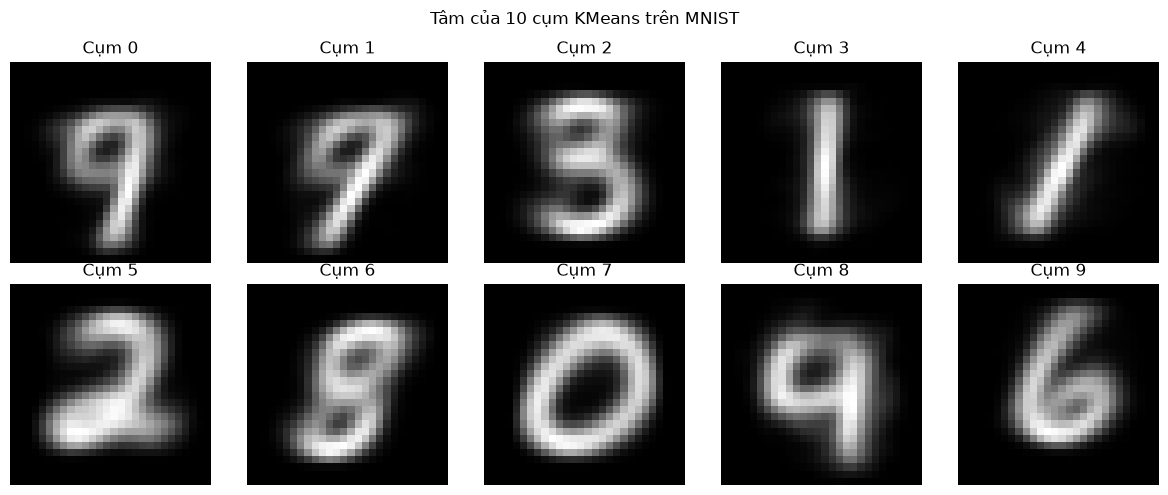

In [5]:
print("NguyenDucTinh - 6451071077")

# Lấy tâm của các cụm
centers = kmeans.cluster_centers_

# Hiển thị tâm cụm dưới dạng ảnh 28x28
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    center_image = centers[i].reshape(28, 28)

    plt.imshow(center_image, cmap='gray')

    plt.title("Cụm " + str(i))
    plt.axis('off')

plt.suptitle("Tâm của 10 cụm KMeans trên MNIST")

plt.tight_layout()
plt.show()

## So sánh cụm với nhãn lớp thực tế

In [6]:
print("NguyenDucTinh - 6451071077")

# Tạo ma trận so sánh giữa nhãn thực tế và nhãn cụm
cm = confusion_matrix(y_sample, y_cluster)

print("Ma trận so sánh nhãn thực tế và nhãn cụm:")
print(cm)

# Tạo ma trận phân bố giữa các cụm và nhãn
contingency = contingency_matrix(y_sample, y_cluster)

# Tìm cách ánh xạ cụm với nhãn thực tế tối ưu
row_ind, col_ind = linear_sum_assignment(-contingency)

# Tạo bảng ánh xạ cụm sang nhãn thực tế
cluster_to_label = {}

for label, cluster in zip(row_ind, col_ind):
    cluster_to_label[cluster] = label

print("\nBảng ánh xạ cụm sang nhãn thực tế:")

for cluster in sorted(cluster_to_label):
    print(
        "Cụm", cluster,
        "-> Nhãn", cluster_to_label[cluster]
    )

# Chuyển nhãn cụm thành nhãn dự đoán
y_pred = np.array([
    cluster_to_label[cluster]
    for cluster in y_cluster
])

print("\n10 nhãn thực tế đầu tiên:")
print(y_sample[:10])

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred[:10])

NguyenDucTinh - 6451071077
Ma trận so sánh nhãn thực tế và nhãn cụm:
[[  2   4  30   0   6   6 109 766  20  41]
 [  0   2   0 610 475   2   2   0   0   2]
 [  7  11  55  55  77 689  22   5  44  29]
 [ 27   8 641  52  29  36 185   6   8   8]
 [302 260   0  10  27   1   1   0 357  22]
 [ 43  59 325  27 131   2 261  12  32  27]
 [  0   0   4  32  39   9  15  14 101 767]
 [422 459   1  40  55   3   2   2  76   0]
 [ 32  42 240  50  82  12 484   5  19  13]
 [419 287  14  21   9   0   6   5 248   1]]

Bảng ánh xạ cụm sang nhãn thực tế:
Cụm 0 -> Nhãn 9
Cụm 1 -> Nhãn 7
Cụm 2 -> Nhãn 3
Cụm 3 -> Nhãn 1
Cụm 4 -> Nhãn 5
Cụm 5 -> Nhãn 2
Cụm 6 -> Nhãn 8
Cụm 7 -> Nhãn 0
Cụm 8 -> Nhãn 4
Cụm 9 -> Nhãn 6

10 nhãn thực tế đầu tiên:
[7 3 8 9 3 9 7 7 5 4]

10 nhãn dự đoán đầu tiên:
[9 3 8 7 8 9 9 9 3 4]


## Đánh giá kết quả gom cụm

In [7]:
print("NguyenDucTinh - 6451071077")

# Tính độ chính xác sau khi ánh xạ cụm
accuracy = accuracy_score(y_sample, y_pred)

# Tính Adjusted Rand Index
ari = adjusted_rand_score(y_sample, y_cluster)

# Tính Normalized Mutual Information
nmi = normalized_mutual_info_score(y_sample, y_cluster)

print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH K-MEANS")

print("Accuracy:", round(accuracy, 4))
print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))

# Báo cáo phân loại sau khi ánh xạ
print("\nBáo cáo phân loại:")

print(
    classification_report(
        y_sample,
        y_pred,
        zero_division=0
    )
)

NguyenDucTinh - 6451071077
KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH K-MEANS
Accuracy: 0.5323
ARI: 0.352
NMI: 0.478

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.94      0.78      0.85       984
           1       0.68      0.56      0.61      1093
           2       0.91      0.69      0.79       994
           3       0.49      0.64      0.55      1000
           4       0.39      0.36      0.38       980
           5       0.14      0.14      0.14       919
           6       0.84      0.78      0.81       981
           7       0.41      0.43      0.42      1060
           8       0.45      0.49      0.47       979
           9       0.33      0.41      0.37      1010

    accuracy                           0.53     10000
   macro avg       0.56      0.53      0.54     10000
weighted avg       0.56      0.53      0.54     10000



## Trực quan hóa ma trận so sánh

NguyenDucTinh - 6451071077


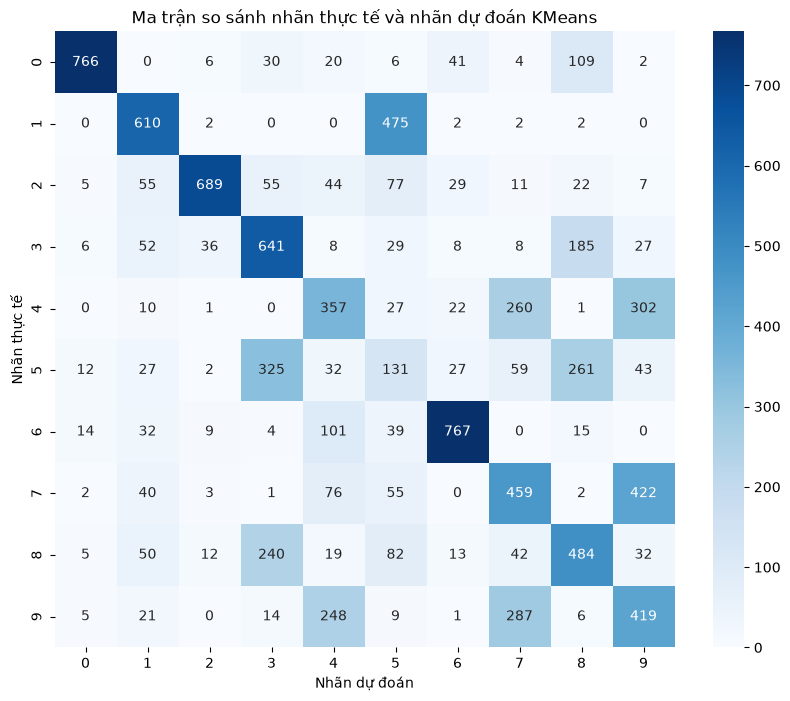

In [8]:
print("NguyenDucTinh - 6451071077")

# Ma trận so sánh sau khi ánh xạ cụm
cm_mapped = confusion_matrix(y_sample, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_mapped,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Ma trận so sánh nhãn thực tế và nhãn dự đoán KMeans")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")

plt.show()

## Biểu đồ phân bố số lượng mẫu trong từng cụm

NguyenDucTinh - 6451071077


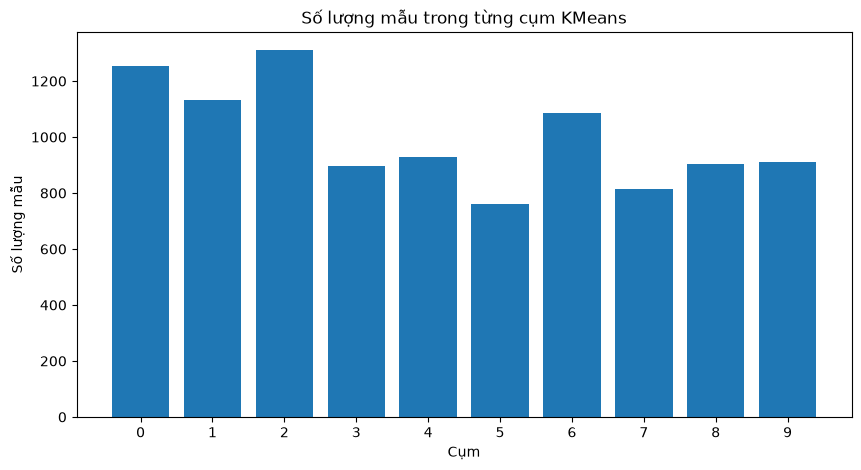

In [9]:
print("NguyenDucTinh - 6451071077")

# Đếm số lượng mẫu trong từng cụm
cluster_counts = np.bincount(y_cluster, minlength=10)

plt.figure(figsize=(10, 5))

plt.bar(
    range(10),
    cluster_counts
)

plt.title("Số lượng mẫu trong từng cụm KMeans")
plt.xlabel("Cụm")
plt.ylabel("Số lượng mẫu")

plt.xticks(range(10))

plt.show()

## So sánh kết quả gom cụm và nhãn thực tế

NguyenDucTinh - 6451071077


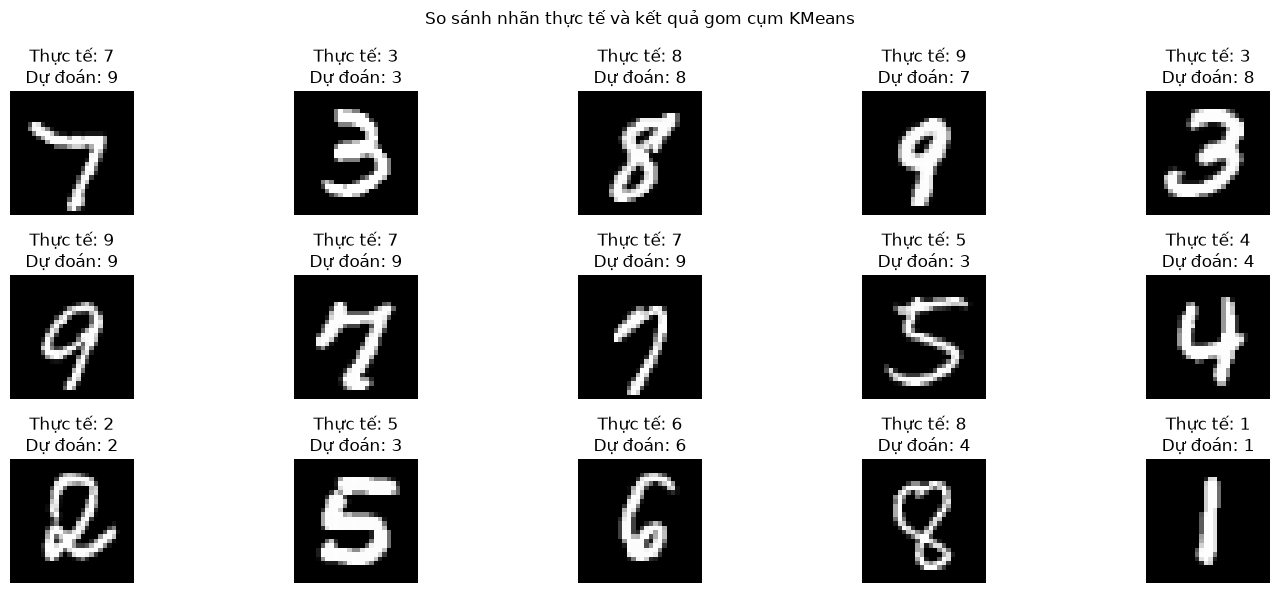

In [10]:
print("NguyenDucTinh - 6451071077")

# Hiển thị một số ảnh cùng nhãn thực tế và nhãn dự đoán
plt.figure(figsize=(15, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[indices[i]], cmap='gray')

    plt.title(
        "Thực tế: " + str(y_sample[i]) +
        "\nDự đoán: " + str(y_pred[i])
    )

    plt.axis('off')

plt.suptitle("So sánh nhãn thực tế và kết quả gom cụm KMeans")

plt.tight_layout()
plt.show()